In [1]:
import matplotlib.pyplot as plt

def show(title, image, cmap='gray'):
    plt.figure(figsize=(4,4))
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

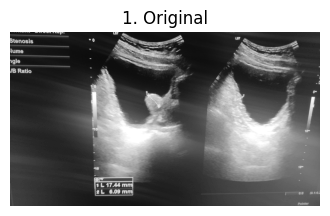

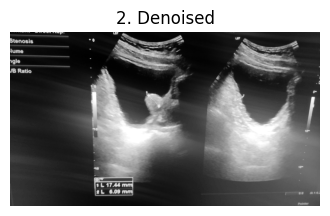

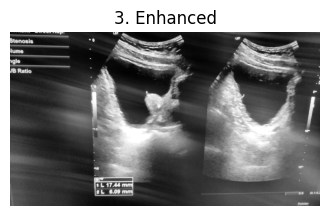

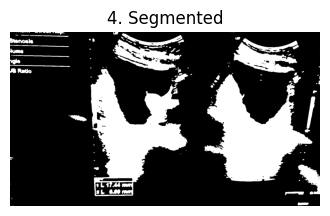

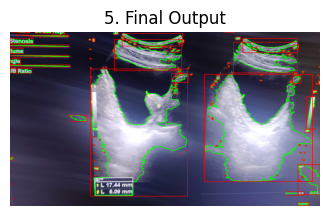

In [2]:
import cv2
import matplotlib.pyplot as plt

def show(title, image, cmap='gray'):
    plt.figure(figsize=(4,4))
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

# Load
img = cv2.imread("image2.jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

show("1. Original", gray)

# Preprocessing
blur = cv2.medianBlur(gray, 5)
show("2. Denoised", blur)

# Enhancement (CLAHE)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
enhanced = clahe.apply(blur)
show("3. Enhanced", enhanced)

# Segmentation
_, thresh = cv2.threshold(enhanced, 120, 255, cv2.THRESH_BINARY)
show("4. Segmented", thresh)

# Contours
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

output = img_rgb.copy()
cv2.drawContours(output, contours, -1, (0,255,0), 2)

# Bounding boxes
for cnt in contours:
    x,y,w,h = cv2.boundingRect(cnt)
    cv2.rectangle(output, (x,y), (x+w,y+h), (255,0,0), 2)

show("5. Final Output", output, cmap=None)